In [9]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

SEED = 42
IMG_SIZE = 160
BATCH_SIZE = 32
EPOCHS_CNN = 12
EPOCHS_MOBILENET = 8

tf.random.set_seed(SEED)
np.random.seed(SEED)

OUTPUT_DIR = "/content/flower_project_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.21.0
GPU available: False


In [11]:
!pip install -U importlib-resources tensorflow-datasets

In [12]:
import tensorflow as tf
import tensorflow_datasets as tfds
import importlib_resources

print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("importlib_resources installed successfully")

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
importlib_resources installed successfully


In [13]:
(train_raw, val_raw, test_raw), info = tfds.load(
    "tf_flowers",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True,
    with_info=True
)

CLASS_NAMES = info.features["label"].names
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.DJ8PCU_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Number of classes: 5


In [14]:
def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    return image, label

def prepare_dataset(dataset, training=False):
    dataset = dataset.map(
        preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(1000, seed=SEED)

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = prepare_dataset(train_raw, training=True)
val_ds = prepare_dataset(val_raw)
test_ds = prepare_dataset(test_raw)

print("Dataset preprocessing completed.")

Dataset preprocessing completed.


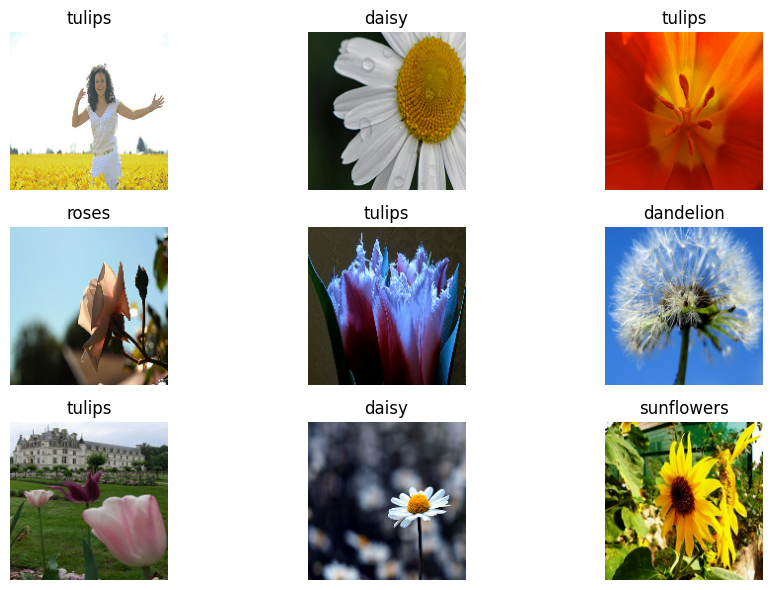

In [15]:
plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/sample_images.png")
plt.show()

In [16]:
def build_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        tf.keras.layers.Rescaling(1.0 / 255),

        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(64, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(128, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

cnn_model = build_cnn()
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
start_time = time.time()

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN
)

cnn_time = time.time() - start_time

cnn_model.save(f"{OUTPUT_DIR}/cnn_model.keras")

print("CNN training time:", round(cnn_time, 2), "seconds")

Epoch 1/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 208s 3s/step - accuracy: 0.3546 - loss: 1.4300 - val_accuracy: 0.4555 - val_loss: 1.2389
Epoch 2/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.4644 - loss: 1.2179 - val_accuracy: 0.5136 - val_loss: 1.1779
Epoch 3/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.5181 - loss: 1.1435 - val_accuracy: 0.5699 - val_loss: 1.1230
Epoch 4/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 147s 2s/step - accuracy: 0.5625 - loss: 1.0881 - val_accuracy: 0.5408 - val_loss: 1.1015
Epoch 5/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 136s 2s/step - accuracy: 0.5718 - loss: 1.0433 - val_accuracy: 0.6116 - val_loss: 1.0306
Epoch 6/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - accuracy: 0.6100 - loss: 1.0195 - val_accuracy: 0.6116 - val_loss: 1.0053
Epoch 7/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - accuracy: 0.6248 - loss: 0.9774 - val_accuracy: 0.6134 - val_loss: 0.9922
Epoch 8/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step - accuracy: 0.6314 - loss: 0.9652 - val_accuracy: 0.6443 - v

In [18]:
def build_mobilenet():
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )

    base_model.trainable = False

    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = tf.keras.layers.Rescaling(
        scale=1.0 / 127.5,
        offset=-1
    )(inputs)

    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

mobilenet_model = build_mobilenet()
mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [19]:
start_time = time.time()

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_MOBILENET
)

mobilenet_time = time.time() - start_time

mobilenet_model.save(f"{OUTPUT_DIR}/mobilenet_model.keras")

print("MobileNet training time:", round(mobilenet_time, 2), "seconds")

Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 81s 930ms/step - accuracy: 0.6392 - loss: 0.9443 - val_accuracy: 0.8312 - val_loss: 0.4921
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 66s 815ms/step - accuracy: 0.8260 - loss: 0.4808 - val_accuracy: 0.8730 - val_loss: 0.3856
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 73s 706ms/step - accuracy: 0.8758 - loss: 0.3605 - val_accuracy: 0.8711 - val_loss: 0.3503
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 56s 689ms/step - accuracy: 0.8918 - loss: 0.3164 - val_accuracy: 0.8820 - val_loss: 0.3312
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 66s 814ms/step - accuracy: 0.9039 - loss: 0.2755 - val_accuracy: 0.8929 - val_loss: 0.3298
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 73s 699ms/step - accuracy: 0.9140 - loss: 0.2477 - val_accuracy: 0.8911 - val_loss: 0.3013
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 81s 690ms/step - accuracy: 0.9241 - loss: 0.2236 - val_accuracy: 0.8875 - val_loss: 0.3024
Epoch 8/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 82s 695ms/step - accuracy: 0.9319 - loss: 0.2012 - val_accuracy: 0.

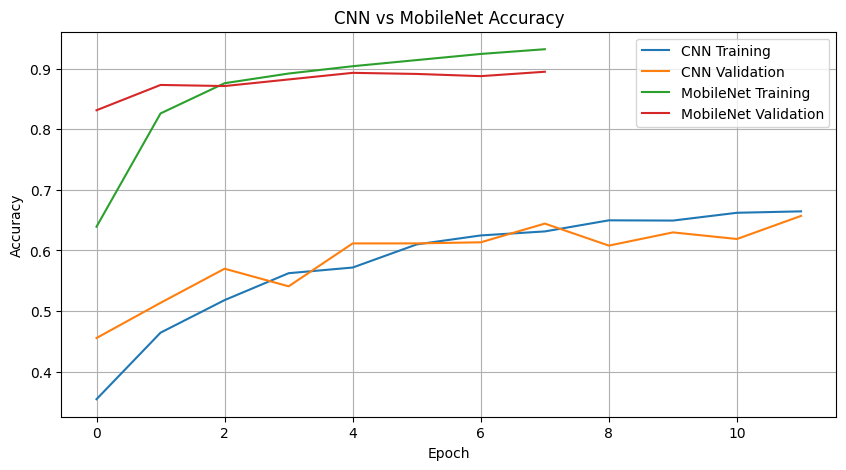

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    cnn_history.history["accuracy"],
    label="CNN Training"
)
plt.plot(
    cnn_history.history["val_accuracy"],
    label="CNN Validation"
)
plt.plot(
    mobilenet_history.history["accuracy"],
    label="MobileNet Training"
)
plt.plot(
    mobilenet_history.history["val_accuracy"],
    label="MobileNet Validation"
)

plt.title("CNN vs MobileNet Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(f"{OUTPUT_DIR}/accuracy_curves.png")
plt.show()


CNN Classification Report
              precision    recall  f1-score   support

   dandelion       0.67      0.71      0.69       112
       daisy       0.67      0.78      0.72        95
      tulips       0.69      0.70      0.69       134
  sunflowers       0.77      0.84      0.80       102
       roses       0.67      0.45      0.54       107

    accuracy                           0.69       550
   macro avg       0.69      0.70      0.69       550
weighted avg       0.69      0.69      0.69       550



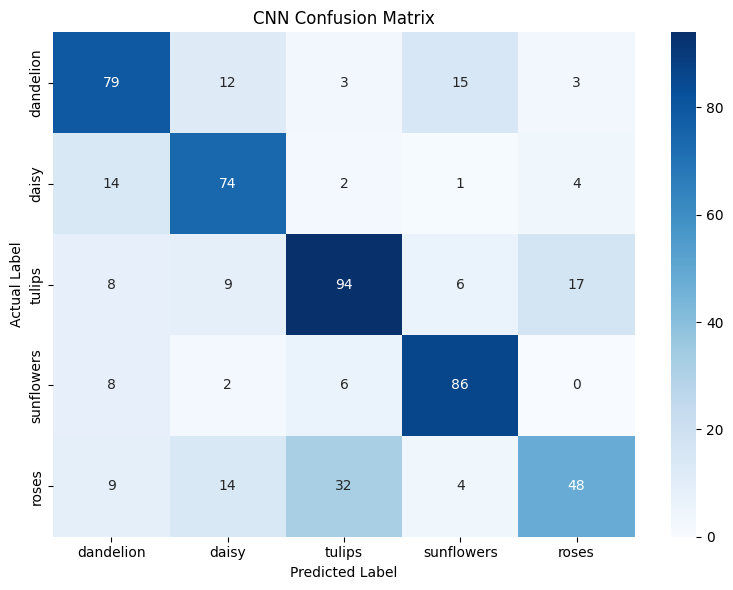


MobileNet Classification Report
              precision    recall  f1-score   support

   dandelion       0.96      0.96      0.96       112
       daisy       0.92      0.91      0.91        95
      tulips       0.89      0.89      0.89       134
  sunflowers       0.88      0.93      0.90       102
       roses       0.91      0.88      0.90       107

    accuracy                           0.91       550
   macro avg       0.91      0.91      0.91       550
weighted avg       0.91      0.91      0.91       550



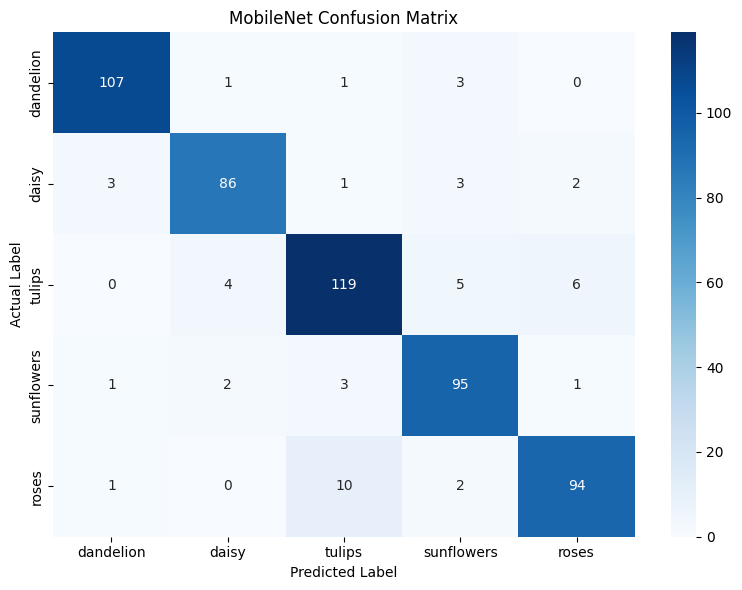

In [21]:
def evaluate_model(model, dataset, model_name):
    y_true = np.concatenate([
        labels.numpy() for _, labels in dataset
    ])

    probabilities = model.predict(dataset, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    )

    print(f"\n{model_name} Classification Report")
    print(classification_report(
        y_true, y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_true, y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/{model_name.lower()}_confusion_matrix.png")
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

cnn_results = evaluate_model(cnn_model, test_ds, "CNN")
mobilenet_results = evaluate_model(
    mobilenet_model, test_ds, "MobileNet"
)

In [22]:
results_df = pd.DataFrame([
    cnn_results,
    mobilenet_results
])

results_df["Training Time (seconds)"] = [
    cnn_time,
    mobilenet_time
]

print(results_df.round(4))

results_df.to_csv(
    f"{OUTPUT_DIR}/model_comparison.csv",
    index=False
)

results_df.to_json(
    f"{OUTPUT_DIR}/model_comparison.json",
    orient="records",
    indent=4
)

       Model  Accuracy  Precision  Recall  F1-Score  Training Time (seconds)
0        CNN    0.6927     0.6908  0.6927    0.6864                1732.2076
1  MobileNet    0.9109     0.9113  0.9109    0.9109                 578.7787


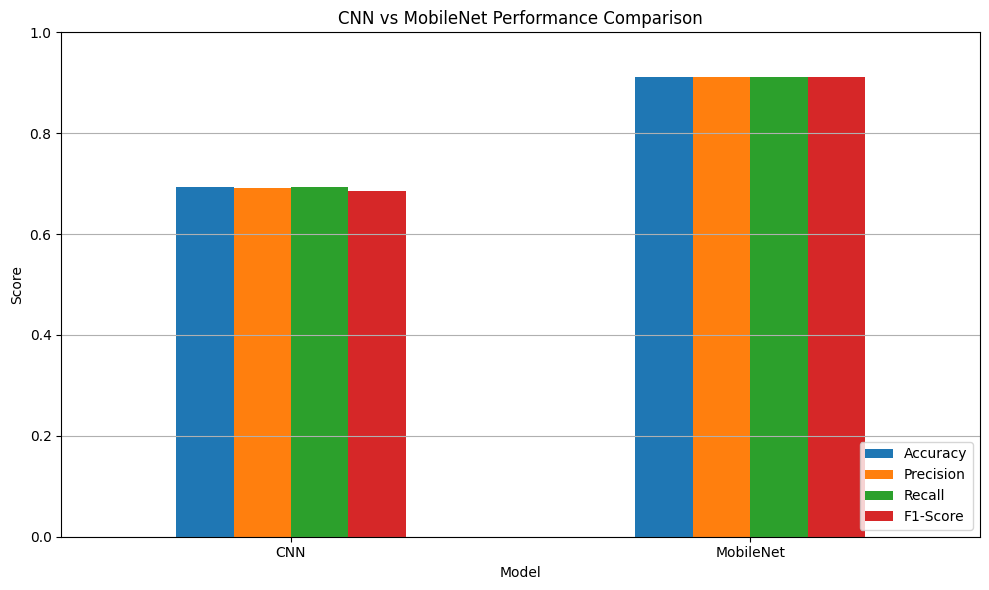

In [23]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("CNN vs MobileNet Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIR}/model_comparison.png")
plt.show()

In [25]:
report = {
    "project": "Flower Classification using CNN and MobileNet",
    "dataset": "TF Flowers",
    "image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "cnn_epochs": EPOCHS_CNN,
    "mobilenet_epochs": EPOCHS_MOBILENET,
    "results": [
        {
            key: (
                float(value)
                if isinstance(value, (np.floating, np.integer))
                else value
            )
            for key, value in result.items()
        }
        for result in [cnn_results, mobilenet_results]
    ],
    "training_time_seconds": {
        "CNN": float(cnn_time),
        "MobileNet": float(mobilenet_time)
    }
}

with open(f"{OUTPUT_DIR}/final_report.json", "w") as f:
    json.dump(report, f, indent=4)

print("All results saved in:", OUTPUT_DIR)
print(os.listdir(OUTPUT_DIR))

All results saved in: /content/flower_project_results
['model_comparison.json', 'model_comparison.csv', 'final_report.json', 'cnn_model.keras', 'accuracy_curves.png', 'mobilenet_model.keras', 'cnn_confusion_matrix.png', 'model_comparison.png', 'mobilenet_confusion_matrix.png', 'sample_images.png']
